# Q06 - Creative Product Agent: GA + Semi-Supervised Learning

Same code as `q06_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q6 - A creative agent that suggests modifications to an existing product.

Product   : a smart water bottle, described by 8 genes.
Learning  : semi-supervised (self-training) - 40 labelled past launches + 400 unlabelled ideas.
Creating  : a genetic algorithm whose fitness = predicted success + novelty - cost.
Co-operate: three agents (designer, usability critic, cost) evolve as islands and share genes.
"""
import itertools
import os
import random

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.semi_supervised import SelfTrainingClassifier

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
os.makedirs("images", exist_ok=True)
random.seed(4)
np.random.seed(4)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

GENES = {
    "capacity": ["500 ml", "750 ml", "1 L"],
    "material": ["plastic", "steel", "glass"],
    "sensor": ["no sensor", "intake tracker", "temp sensor", "UV purifier"],
    "display": ["no display", "LED ring", "mini screen"],
    "app": ["no app", "reminder app", "health sync"],
    "power": ["coin cell", "USB-C", "solar"],
    "shape": ["classic", "foldable", "modular cap"],
    "price": ["budget", "mid", "premium"],
}
SIZES = [len(v) for v in GENES.values()]
CURRENT = (0, 0, 0, 0, 0, 0, 0, 0)  # today's bottle: plain, plastic, budget
PRODUCT_LINE = [CURRENT, (1, 1, 0, 0, 0, 0, 0, 1), (0, 0, 2, 1, 0, 1, 0, 1),
                (2, 1, 0, 0, 0, 0, 1, 1), (1, 2, 0, 0, 0, 0, 0, 2)]


def market_truth(v: tuple) -> bool:
    """Hidden market behaviour. The agent never sees this; it only sees a few labels."""
    cap, mat, sen, dis, app, pwr, shp, prc = v
    s = [0, .5, .2][cap] + [0, .8, .4][mat] + [0, 1, .4, 1.2][sen] + [0, .6, .3][dis]
    s += [0, .6, .9][app] + [0, .5, .3][pwr] + [0, .3, .6][shp]
    s += 0.8 * (sen == 1 and app > 0) - 0.6 * (sen > 0 and app == 0)
    s += 0.5 * (sen == 3 and mat == 1) - 0.8 * (dis == 2 and pwr == 0)
    features = (sen > 0) + (dis > 0) + (app > 0) + (pwr == 2) + (shp > 0)
    fair_price = 0 if features <= 1 else 1 if features <= 3 else 2
    return s - 0.7 * abs(prc - fair_price) > 2.3


def cost(v: tuple) -> float:
    table = [[0, .05, .08], [0, .25, .2], [0, .2, .15, .35], [0, .1, .25],
             [0, .05, .1], [0, .05, .2], [0, .15, .1], [0, 0, 0]]
    return sum(t[g] for t, g in zip(table, v)) / 1.4


def novelty(v: tuple) -> float:
    return min(sum(a != b for a, b in zip(v, p)) for p in PRODUCT_LINE) / len(v)


def one_hot(rows: list) -> np.ndarray:
    out = []
    for v in rows:
        out.append(np.concatenate([np.eye(n)[g] for n, g in zip(SIZES, v)]))
    return np.array(out)


def random_variant() -> tuple:
    return tuple(random.randrange(n) for n in SIZES)


def describe(v: tuple) -> str:
    return ", ".join(opts[g] for opts, g in zip(GENES.values(), v))


# ---------------- semi-supervised learning: the learn set evolves ----------------
labelled, labels = [], []
while len(labelled) < 40:  # past launches: 20 hits and 20 flops
    v = random_variant()
    if v not in labelled and int(market_truth(v)) == (len(labelled) % 2):
        labelled.append(v)
        labels.append(int(market_truth(v)))
pool = [random_variant() for _ in range(400)]
test = [random_variant() for _ in range(600)]
test_y = np.array([int(market_truth(v)) for v in test])


def fit_ssl(lab: list, y: list, unl: list) -> SelfTrainingClassifier:
    X = one_hot(lab + unl)
    base = LogisticRegression(C=2.0, max_iter=500)
    model = SelfTrainingClassifier(base, threshold=0.85, max_iter=10)
    model.fit(X, np.array(y + [-1] * len(unl)))
    return model


print("Q6  Creative product agent: GA + semi-supervised learning (smart water bottle)")
print("  today's bottle:", describe(CURRENT))
sup = LogisticRegression(C=2.0, max_iter=500).fit(one_hot(labelled), labels)
print(f"  share of ideas that really succeed: {test_y.mean():.0%}")
sup_acc = np.mean(sup.predict(one_hot(test)) == test_y)
print(f"  supervised only (40 labels): test accuracy {sup_acc:.2f}")
print("  round | labelled | pseudo-labelled | test accuracy  (self-training, 400 unlabelled)")
growth = []
model = fit_ssl(labelled, labels, pool)
n_pseudo = int((model.transduction_[len(labelled):] != -1).sum())
growth.append((len(labelled) + n_pseudo, float(np.mean(model.predict(one_hot(test)) == test_y))))
print(f"      0 | {len(labelled):>8} | {n_pseudo:>15} | {growth[0][1]:.2f}")
model = fit_ssl(labelled, labels, pool)
ALL = list(itertools.product(*[range(n) for n in SIZES]))
PROBS = model.predict_proba(one_hot(ALL))[:, 1]
CACHE = dict(zip(ALL, PROBS))


def p_success(v: tuple) -> float:
    return float(CACHE[v])


def value(v: tuple) -> float:
    """Shared company view used by the blackboard to compare ideas."""
    return p_success(v) + 0.3 * novelty(v) - 0.3 * cost(v)


# ---------------- genetic algorithm agents ----------------
AGENTS = {"designer": (0.5, 1.0, 0.0), "usability critic": (1.0, 0.1, 0.1),
          "cost agent": (0.6, 0.0, 0.8)}  # weights for (success, novelty, cost)


def agent_fitness(v: tuple, w: tuple) -> float:
    return w[0] * p_success(v) + w[1] * novelty(v) - w[2] * cost(v)


def evolve(islands: dict, gens: int = 30, migrate: bool = False) -> tuple:
    pops = {name: [random_variant() for _ in range(20)] for name in islands}
    history = []
    for gen in range(gens):
        for name, w in islands.items():
            pop = sorted(pops[name], key=lambda v: -agent_fitness(v, w))
            children = pop[:2]                                   # elitism
            while len(children) < len(pop):
                p1, p2 = (max(random.sample(pop, 3), key=lambda v: agent_fitness(v, w))
                          for _ in range(2))                     # tournament selection
                child = tuple(a if random.random() < 0.5 else b for a, b in zip(p1, p2))
                child = tuple(random.randrange(n) if random.random() < 0.15 else g
                              for n, g in zip(SIZES, child))     # mutation
                children.append(child)
            pops[name] = children
        if migrate and gen % 5 == 4:                             # share best genes
            best = {n: sorted(p, key=lambda v: -agent_fitness(v, islands[n]))[:2]
                    for n, p in pops.items()}
            for n in pops:
                pops[n] = pops[n][:-4] + [v for m in pops if m != n for v in best[m]]
        history.append(max(value(v) for p in pops.values() for v in p))
    return sorted({v for p in pops.values() for v in p}, key=value, reverse=True), history


print("GA AGENTS (20 ideas per agent, 30 generations, average of 10 seeds)")
curves, finals = {}, {}
for name in list(AGENTS) + ["co-operative"]:
    runs = []
    for seed in range(10):
        random.seed(seed)
        if name == "co-operative":
            ranked, hist = evolve(AGENTS, migrate=True)
        else:
            ranked, hist = evolve({name: AGENTS[name]})
        runs.append((hist, ranked[0]))
    curves[name] = np.mean([h for h, _ in runs], axis=0)
    finals[name] = np.mean([value(v) for _, v in runs])
    hits = np.mean([market_truth(v) for _, v in runs])
    print(f"  {name:<17}| mean best value {finals[name]:.3f} | really succeed {hits:.0%}")
random.seed(0)
ranked, _ = evolve(AGENTS, migrate=True)
print("TOP 3 MODIFICATIONS (choices, not answers) + simulated market test")
for i, v in enumerate(ranked[:3], 1):
    verdict = "success" if market_truth(v) else "flop"
    print(f"  {i}. {describe(v)}")
    print(f"     value {value(v):.3f} | predicted P {p_success(v):.2f} | market test: {verdict}")
    labelled.append(v)
    labels.append(int(market_truth(v)))
model = fit_ssl(labelled, labels, pool)
acc = float(np.mean(model.predict(one_hot(test)) == test_y))
growth.append((len(labelled) + int((model.transduction_[len(labelled):] != -1).sum()), acc))
print(f"  feedback: 3 launch results added as true labels -> accuracy {acc:.2f}")

# ---------------- charts ----------------
fig, ax = plt.subplots(figsize=(8.5, 4))
colors = {"designer": "#7b5ea7", "usability critic": "#3a6ea5", "cost agent": "#d98e04",
          "co-operative": "#2a9d8f"}
for name, curve in curves.items():
    ax.plot(range(1, len(curve) + 1), curve, lw=2.6 if name == "co-operative" else 1.6,
            color=colors[name], label=name + (" (islands + migration)" if name == "co-operative"
                                              else " alone"))
ax.set_xlabel("generation")
ax.set_ylabel("best shared value in population")
ax.set_title("Single agents vs co-operative agents (same 30 generations)")
ax.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig("images/q06_chart1_agents.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 3.6))
rounds = [f"round {i}" for i in range(len(growth) - 1)] + ["after\nmarket test"]
ax.bar(rounds, [g[0] for g in growth], color="#a8c5e2", edgecolor="#3a6ea5")
ax.set_ylabel("size of labelled set")
for i, (n, _) in enumerate(growth):
    ax.text(i, n + 3, str(n), ha="center", fontsize=9)
ax2 = ax.twinx()
ax2.plot(rounds, [g[1] for g in growth], "o-", color="#e76f51", lw=2)
ax2.set_ylabel("test accuracy", color="#e76f51")
ax2.set_ylim(0.5, 1.0)
ax2.grid(False)
ax.set_title("The learn set evolves: pseudo-labels + market feedback")
fig.tight_layout()
fig.savefig("images/q06_chart2_learn_set.png")
plt.close(fig)
print("charts saved to images/")


Q6  Creative product agent: GA + semi-supervised learning (smart water bottle)
  today's bottle: 500 ml, plastic, no sensor, no display, no app, coin cell, classic, budget
  share of ideas that really succeed: 40%
  supervised only (40 labels): test accuracy 0.73
  round | labelled | pseudo-labelled | test accuracy  (self-training, 400 unlabelled)
      0 |       40 |             305 | 0.72


GA AGENTS (20 ideas per agent, 30 generations, average of 10 seeds)


  designer         | mean best value 1.049 | really succeed 90%


  usability critic | mean best value 1.121 | really succeed 40%


  cost agent       | mean best value 1.060 | really succeed 0%


  co-operative     | mean best value 1.117 | really succeed 70%
TOP 3 MODIFICATIONS (choices, not answers) + simulated market test
  1. 1 L, plastic, intake tracker, LED ring, reminder app, coin cell, modular cap, premium
     value 1.110 | predicted P 1.00 | market test: success
  2. 1 L, plastic, temp sensor, LED ring, reminder app, coin cell, modular cap, premium
     value 1.081 | predicted P 1.00 | market test: success
  3. 750 ml, plastic, no sensor, no display, reminder app, coin cell, modular cap, mid
     value 1.067 | predicted P 1.00 | market test: flop
  feedback: 3 launch results added as true labels -> accuracy 0.76


charts saved to images/


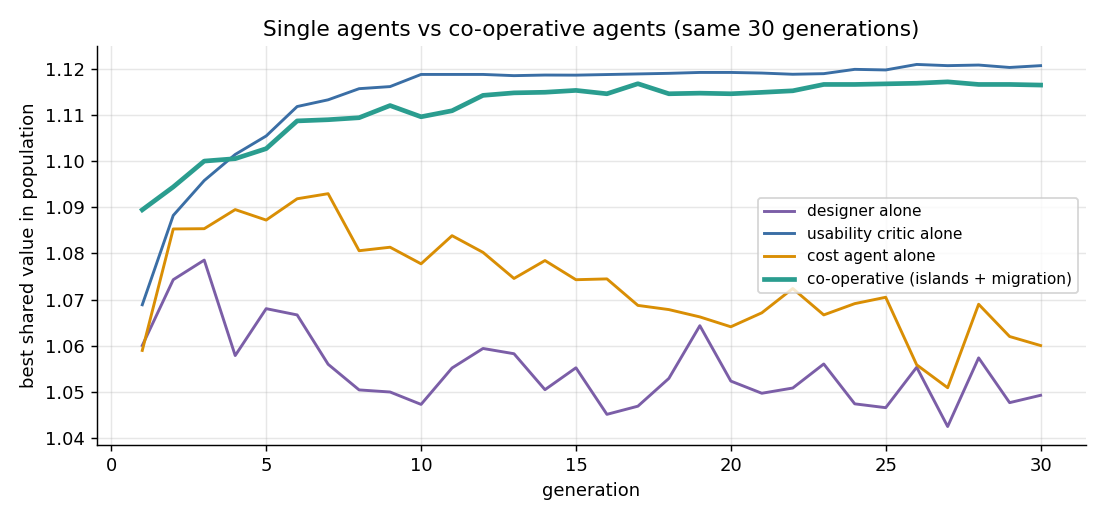

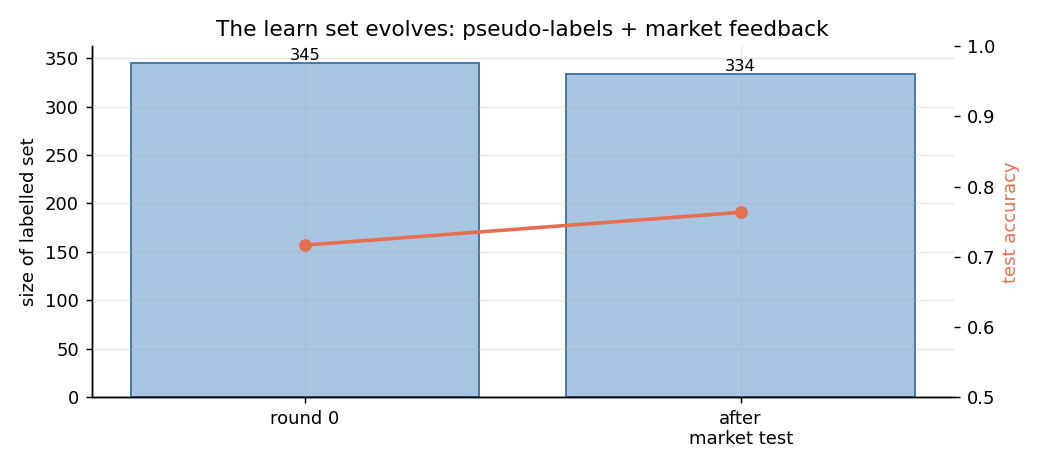

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q06_chart*.png')):
    display(Image(p))